In [30]:
import torch
import torch.nn as nn
from transformers import AutoModelForCausalLM ,AutoTokenizer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.cm as cm
from transformers.generation.logits_process import LogitsProcessorList,TopKLogitsWarper
from typing import List
import torch.nn.functional as F

In [3]:
tokenizer=AutoTokenizer.from_pretrained("huggyllama/llama-7b")
model=AutoModelForCausalLM.from_pretrained("huggyllama/llama-7b",
                                          torch_dtype=torch.float16,
                                          device_map="auto",
                                          attn_implementation='sdpa',
                                          output_attentions=True)


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.llama.tokenization_llama_fast.LlamaTokenizerFast'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565 - if you loaded a llama tokenizer from a GGUF file you can ignore this message.


config.json:   0%|          | 0.00/594 [00:00<?, ?B/s]

... (4 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/9.98G [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/generation/configuration_utils.py:820: UserWarning: `return_dict_in_generate` is NOT set to `True`, but `output_attentions` is. When `return_dict_in_generate` is not `True`, `output_attentions` is ignored.
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

In [4]:
model.eval()

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096, padding_idx=0)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
      )
    )
    (norm): LlamaRMSNorm((4096,), eps=1e-06

In [90]:
inputs=tokenizer("Hello,My name is Shreyansh,I study Deep Learninig",return_tensors='pt')


{'input_ids': tensor([[    1, 15043, 29892,  3421,  1024,   338,  1383,  8903,   550, 29882,
         29892, 29902,  6559, 21784, 19530, 29876,   262,   335]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [6]:
with torch.no_grad():
    outputs=model(**inputs,output_hidden_states=True)

`torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True`. Falling back to eager attention. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


In [7]:
hidden_states=outputs.hidden_states

In [8]:
len(hidden_states)

33

In [149]:
layer_range=[1,5,7,10,12,15,17,18,19,20,21,22,24,26,27,28,30,31]
token_range=[0,18]
logits_warper=TopKLogitsWarper(top_k=50,filter_value=float('-inf'))
logits_processor=LogitsProcessorList([])

In [150]:
def logitlens(model,tokenizer,input_ids,outputs,token_range :List[int],layer_range:List[int],logits_warper,logits_processor):
    layer_max_prob=torch.zeros((1,token_range[1]-token_range[0]))
    layer_words=[]
    for i in layer_range:
        hidden_state=outputs['hidden_states'][i+1].squeeze(0)
        hidden_state=hidden_state[token_range[0]:token_range[1]].clone().detach()
        logits=model.lm_head(hidden_state).cpu().float()
        logits=F.log_softmax(logits)
        logits_processed=logits_processor(input_ids,logits)
        logits=logits_warper(input_ids,logits_processed)
        probs=F.softmax(logits,dim=-1)
        vals,ids=probs.max(dim=-1)
        layer_max_prob=torch.cat([vals.unsqueeze(0).cpu().detach(),layer_max_prob],dim=0)
        layer_words.append([tokenizer.decode(id,skip_special_tokens=False) for id in ids])
    layer_max_prob=layer_max_prob[:-1]



    return layer_max_prob,layer_words



    

In [151]:
probs,words=logitlens(model,tokenizer,inputs['input_ids'],outputs,token_range,layer_range,logits_warper,logits_processor)

/tmp/ipykernel_35/160347597.py:8: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  logits=F.log_softmax(logits)


In [152]:
def plot(tokens,layer_words,layer_max_prob,token_range=None,layer_range=None,figsize=(20,8)):
    num_layers=len(layer_words)
    num_tokens=len(layer_words[0])
    fig,ax=plt.subplots(figsize=figsize,dpi=150)

    im=ax.imshow(layer_max_prob,cmap='cividis')

    for i in range(num_layers):
        for j in range(num_tokens):
            ax.text(
                j,i,
                layer_words[i][j],
                ha='center',
                va='center',
                color='white' if layer_max_prob[i][j]<0.5 else 'black',
                fontsize=11,
                rotation=30
            )

    ax.set_xticks(np.arange(num_tokens))
    ax.set_yticks(np.arange(num_layers))
    ax.set_xticklabels(
      tokens,
        rotation=45,
        fontsize=10
    )
    ax.set_yticklabels(
        [f"Layer {l}" for l in (layer_range if layer_range else range(num_layers))],
        fontsize=10
    )

    plt.xlabel("Token Positions")
    plt.ylabel("Transformer Layers")
    plt.title("Logit Lens: Predicted Tokens + Probabilities")
    fig.colorbar(im, ax=ax, label="Max Probability")
    plt.tight_layout()
    plt.show()

In [153]:
inputs['input_ids']

tensor([[    1, 15043, 29892,  3421,  1024,   338,  1383,  8903,   550, 29882,
         29892, 29902,  6559, 21784, 19530, 29876,   262,   335]])

In [154]:
tokens=tokenizer.convert_ids_to_tokens(inputs['input_ids'][0].tolist())

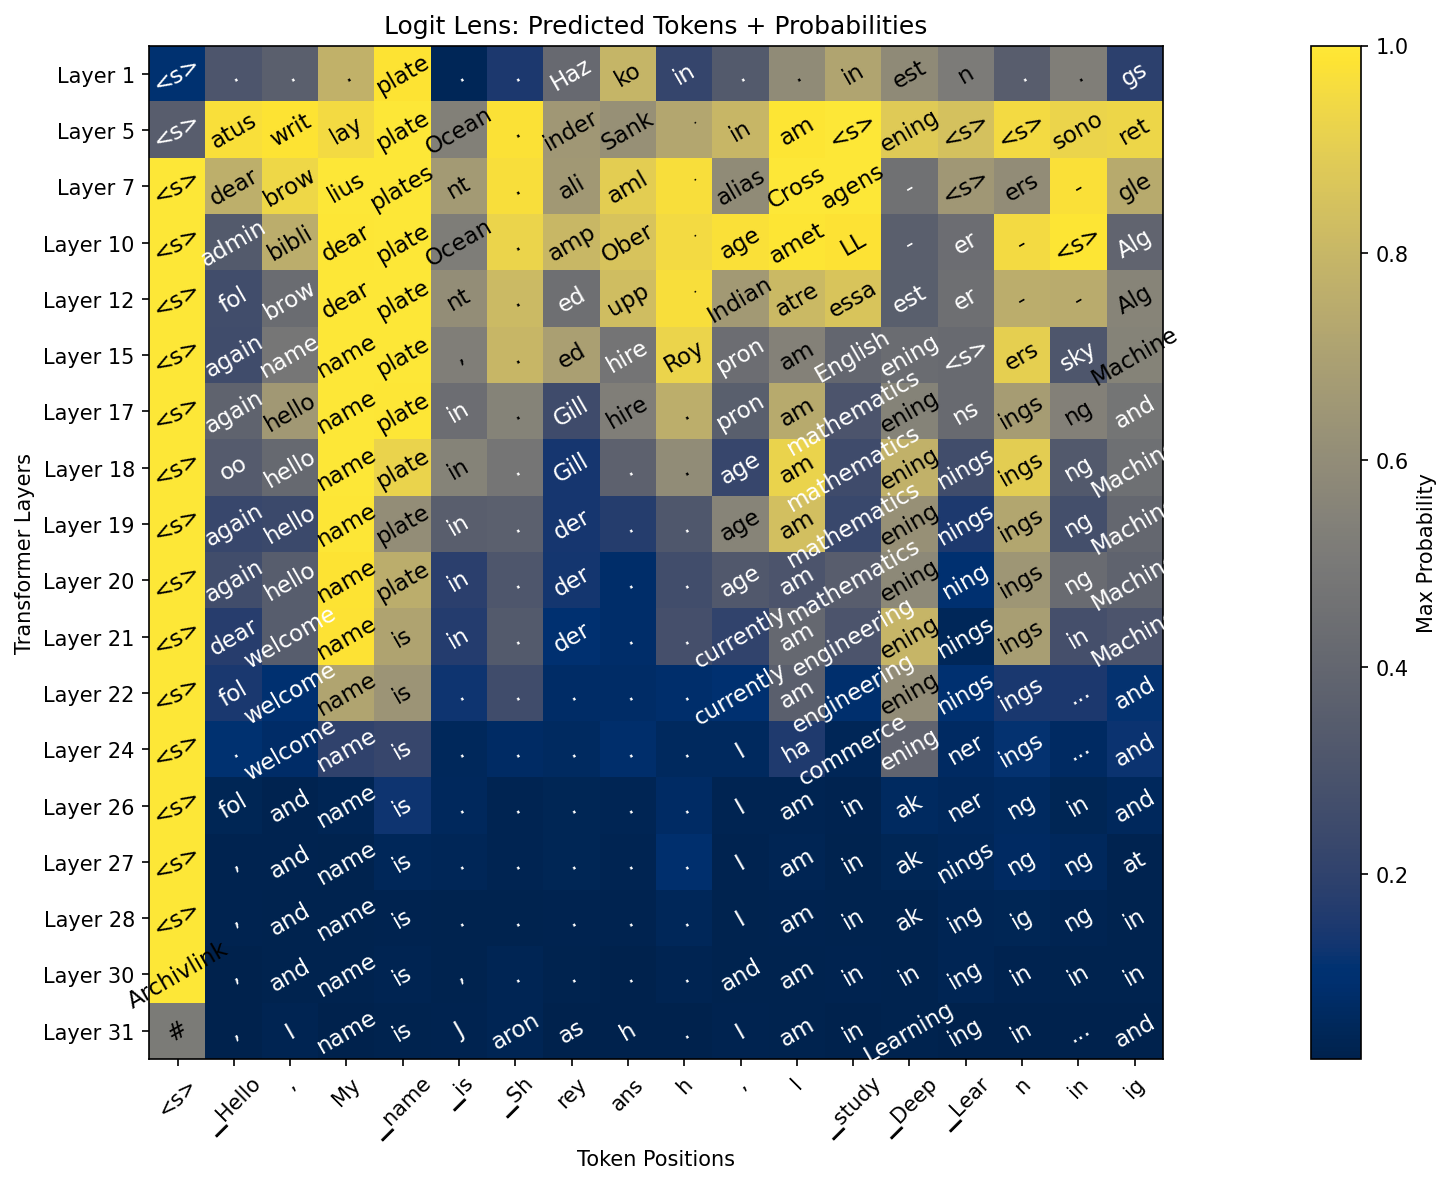

In [155]:
plot(tokens,
    words,
    probs.numpy(),
    token_range,
    layer_range
)
